# 1 km and 500 m flow direction grids for the Colne and Wyre catchments

Cuts catchment-scale copies of the 1 km and 500 m UK flow direction, accumulation and conditioned DEM rasters made in
`2026-11-02_2_uk-flowdir-1km-500m.ipynb`. It covers:

* **Colne** (Hertfordshire/London tributary of the Thames, joining at Staines). Boundary: CEH Integrated
  Hydrological Units, catchment `HA039G13S0001` (outlet at the Thames confluence, 894.6 km²).
* **Wyre** (Lancashire, reaching the sea at Fleetwood). Boundary: Environment Agency WFD Cycle 3 Wyre
  Management Catchment (ID 3119, 448 km²) from the
  [Catchment Data Explorer](https://environment.data.gov.uk/catchment-planning/ManagementCatchment/3119).

**The domains come from the flow directions, not from clipping by the polygons.** Clipping a grid with a
catchment polygon cuts across flow paths. Edge cells inside the polygon end up pointing at cells outside it,
which act as pits at the domain edge, and cells outside that drain in are lost. Instead, each domain is a
set of complete drainage areas:

1. **Main outlet.** If the boundary comes with an outlet point (the IHU catchments do), that point is
   snapped to the nearby cell with the largest upstream area that isn't on a much bigger river. Otherwise
   every cell near the polygon is a candidate, and the one whose upstream area best matches the polygon
   (highest intersection over union, IoU) is chosen. Either way, the outlet's whole upstream area becomes
   the domain.
2. **Extra coastal basins.** Coastal catchments can drain to the sea at several separate points. Whole
   sea-draining basins that are mostly (≥50%) inside the polygon are added (relevant for the Fylde coast
   and Fleetwood peninsula on the Wyre).

Every cell upstream of a domain cell is therefore also in the domain, and the only cells that drain out of
it are its outlets. The polygons are used only to choose the domains and to check how well they match. The
maps at the end overlay the OS Open Rivers network on the modelled drainage, to show how well the flow
directions follow the mapped rivers.

In [1]:
import os
import tomllib
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import numba
import rasterio
import rasterio.features
from rasterio.transform import from_origin
from rasterio.windows import Window
import geopandas as gpd
from shapely.geometry import shape
from scipy import ndimage
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

# Data locations are set in paths.toml in the project root (copy paths.example.toml to make it), or in the
# file named by the PFASE_PATHS environment variable. Relative paths in it are relative to that file
path_config = Path(os.environ.get('PFASE_PATHS', '../paths.toml')).expanduser().resolve()
if not path_config.exists():
    raise FileNotFoundError(f'{path_config} not found. Copy paths.example.toml to paths.toml and set the paths in it')
config = tomllib.loads(path_config.read_text())


def config_path(key):
    return (path_config.parent / Path(config[key]).expanduser()).resolve()

path_data = config_path('data_dir')  # UK grids in, catchment grids out
path_ihu = config_path('ihu_catchments')
path_wyre = config_path('wyre_boundary')
path_rivers = config_path('os_rivers')
RESOLUTIONS = [1000, 500]
needed = [path_ihu, path_wyre, path_rivers] + [path_data / f'flowdir_{res:05d}_bng.tif' for res in RESOLUTIONS]
missing = [p for p in needed if not p.exists()]
if missing:
    raise FileNotFoundError('Inputs not found (paths.example.toml lists their sources; the UK grids come from the '
                            f'UK flowdir notebooks): {", ".join(map(str, missing))}')

## Load the UK grids

`load_grid` reads the UK flow direction, accumulation and conditioned DEM for one resolution. It also labels
each land cell with the last land cell on its path (`terminal`), i.e. the coastal cell where its water reaches
the sea, which is used to find whole coastal basins. `CODES`, `DI` and `DJ` give the ESRI D8 codes (E, SE, S,
SW, W, NW, N, NE) and their row/column offsets. Land never touches the edge of the UK grids, so neighbour
lookups from land cells are always in bounds.

In [2]:
DI = np.array([0, 1, 1, 1, 0, -1, -1, -1])
DJ = np.array([1, 1, 0, -1, -1, -1, 0, 1])
CODES = np.array([1, 2, 4, 8, 16, 32, 64, 128])


@numba.njit
def upstream(fdir, r, c):
    mask = np.zeros(fdir.shape, dtype=np.bool_)
    mask[r, c] = True
    stack = [(r, c)]
    while len(stack) > 0:
        i, j = stack.pop()
        for k in range(8):
            # The neighbour in direction k drains here if it points back the opposite way
            ii, jj = i + DI[k], j + DJ[k]
            if not mask[ii, jj] and fdir[ii, jj] == CODES[(k + 4) % 8]:
                mask[ii, jj] = True
                stack.append((ii, jj))
    return mask


@numba.njit
def terminal(fdir, land):
    ncol = fdir.shape[1]
    term = np.full(fdir.shape, -1, dtype=np.int64)
    for i0 in range(fdir.shape[0]):
        for j0 in range(ncol):
            if not land[i0, j0]:
                continue
            i, j = i0, j0
            while True:
                k = np.searchsorted(CODES, fdir[i, j])
                ii, jj = i + DI[k], j + DJ[k]
                if not land[ii, jj]:
                    break
                i, j = ii, jj
            term[i0, j0] = i * ncol + j
    return term


def downstream_cells(fdir, cells):
    # Row and column of the cell downstream of each (row, col) in `cells`
    k = np.searchsorted(CODES, fdir[cells[:, 0], cells[:, 1]])
    return cells[:, 0] + DI[k], cells[:, 1] + DJ[k]


def load_grid(res):
    g = SimpleNamespace(res=res, tag=f'{res:05d}')
    with rasterio.open(path_data / f'flowdir_{g.tag}_bng.tif') as src:
        g.fdir, g.profile, g.transform, g.crs, g.nodata = src.read(1), src.profile, src.transform, src.crs, src.nodata
    with rasterio.open(path_data / f'flowacc_{g.tag}_bng.tif') as src:
        g.acc = src.read(1)
    with rasterio.open(path_data / f'dem_{g.tag}_bng_conditioned.tif') as src:
        g.dem = src.read(1)
    g.X0, g.Y1 = g.transform.c, g.transform.f
    g.cell_km2 = res**2 / 1e6
    g.land = g.fdir != g.nodata
    g.basin = terminal(g.fdir, g.land)
    return g


grids = {res: load_grid(res) for res in RESOLUTIONS}
crs, NODATA = grids[RESOLUTIONS[0]].crs, int(grids[RESOLUTIONS[0]].nodata)
for g in grids.values():
    print(f'{g.res} m: {g.fdir.shape[1]} x {g.fdir.shape[0]} cells, {g.land.sum()} land')

1000 m: 950 x 1250 cells, 317819 land
500 m: 1900 x 2500 cells, 1270147 land


## Catchment boundaries

The Colne polygon is extracted from the IHU dataset (stored in EPSG:4326) and saved in BNG next to the
downloaded Wyre boundary, so the inputs are all in one place.

In [3]:
ihu = gpd.read_file(path_ihu)
colne = ihu[ihu.S_ID == 'HA039G13S0001'].to_crs(crs)
path_colne = path_data / 'boundaries/colne_ihu-HA039G13S0001/colne_ihu-HA039G13S0001.shp'
path_colne.parent.mkdir(parents=True, exist_ok=True)
colne.to_file(path_colne)

wyre = gpd.read_file(path_wyre).to_crs(crs)
# Polygon and known outlet point (BNG), if there is one. The Wyre is coastal, so has no single outlet point
boundaries = {
    'colne': (colne.union_all(), (colne.EAST.item(), colne.NORTH.item())),
    'wyre': (wyre.union_all(), None),
}
for name, (geom, outlet_xy) in boundaries.items():
    print(f'{name}: {geom.area / 1e6:.1f} km2, outlet point {outlet_xy}')

colne: 894.6 km2, outlet point (503300, 171500)
wyre: 448.1 km2, outlet point None


## Choose the domains

`cell_fraction` gives the fraction of each cell covered by a polygon, by rasterising onto a sub-grid of 1/20 of
a cell. Overlap is area-weighted, so the IoU is in km².

* **With an outlet point:** candidates are cells within 4 km of the point whose upstream area is at most 1.5
  times the polygon's. This rules out the receiving river: the IHU Colne outlet point falls in the 2 km
  Thames cell. The candidate with the largest upstream area is chosen.
* **Without one:** candidates are land cells touching the polygon (buffered by one cell) with at least a
  quarter of the polygon's area upstream, and the one with the best IoU is chosen.

Maximising IoU is only used when there is no outlet point. Near a narrow outlet reach it can stop
upstream of the real outlet: on an earlier, DEM-only version of the 2 km grid it put the Colne outlet at
Uxbridge rather than Staines.

In [4]:
def cell_fraction(g, geom, ss=20):
    frac = np.zeros(g.fdir.shape)
    minx, miny, maxx, maxy = geom.bounds
    c0, c1 = int((minx - g.X0) // g.res) - 1, int((maxx - g.X0) // g.res) + 2
    r0, r1 = int((g.Y1 - maxy) // g.res) - 1, int((g.Y1 - miny) // g.res) + 2
    sub = rasterio.features.rasterize([geom], out_shape=((r1 - r0) * ss, (c1 - c0) * ss),
                                      transform=from_origin(g.X0 + c0 * g.res, g.Y1 - r0 * g.res, g.res / ss, g.res / ss))
    frac[r0:r1, c0:c1] = sub.reshape(r1 - r0, ss, c1 - c0, ss).mean(axis=(1, 3))
    return frac


def iou(g, mask, frac, area_poly):
    inter = (frac * mask).sum() * g.cell_km2
    return inter / (mask.sum() * g.cell_km2 + area_poly - inter)


def rowcol(g, x, y):
    return int((g.Y1 - y) // g.res), int((x - g.X0) // g.res)


def cell_xy(g, r, c):
    return float(g.X0 + (c + 0.5) * g.res), float(g.Y1 - (r + 0.5) * g.res)


def select_domain(g, geom, outlet_xy=None):
    frac = cell_fraction(g, geom)
    area_poly = geom.area / 1e6
    if outlet_xy is not None:
        r0, c0 = rowcol(g, *outlet_xy)
        rad = round(4000 / g.res)
        near = np.zeros_like(g.land)
        near[r0 - rad:r0 + rad + 1, c0 - rad:c0 + rad + 1] = True
        near &= g.land & (g.acc * g.cell_km2 <= 1.5 * area_poly)
        _, r, c = max((g.acc[r, c], r, c) for r, c in np.argwhere(near))
        domain = upstream(g.fdir, r, c)
        print(f'  outlet point {outlet_xy} snapped to cell centre {cell_xy(g, r, c)}')
    else:
        near = g.land & (cell_fraction(g, geom.buffer(g.res), ss=4) > 0) & (g.acc * g.cell_km2 >= 0.25 * area_poly)
        scores = [(iou(g, upstream(g.fdir, r, c), frac, area_poly), r, c) for r, c in np.argwhere(near)]
        best, r, c = max(scores)
        domain = upstream(g.fdir, r, c)
        print(f'  {len(scores)} candidate outlets; best IoU {best:.3f} with outlet at cell centre {cell_xy(g, r, c)}')
    # Add whole sea-draining basins that lie mostly inside the polygon
    added = []
    for b in np.unique(g.basin[g.land & (frac > 0) & ~domain]):
        in_basin = g.basin == b
        if frac[in_basin].mean() >= 0.5:
            domain |= in_basin
            added.append(in_basin.sum())
    if added:
        print(f'  added {len(added)} coastal basins mostly inside the polygon: {sum(added)} cells '
              f'({sum(added) * g.cell_km2:.1f} km2), largest {max(added)} cells')
    return domain, frac, area_poly


domains = {}
for g in grids.values():
    for name, (geom, outlet_xy) in boundaries.items():
        print(f'{name}, {g.res} m')
        domain, frac, area_poly = select_domain(g, geom, outlet_xy)
        domains[g.res, name] = dict(mask=domain, frac=frac, area_poly=area_poly)
        area = domain.sum() * g.cell_km2
        print(f'  domain {domain.sum()} cells = {area:.0f} km2 (polygon {area_poly:.1f} km2, {100 * (area - area_poly) / area_poly:+.1f}%); '
              f'IoU {iou(g, domain, frac, area_poly):.3f}; {100 * (frac * domain).sum() * g.cell_km2 / area_poly:.1f}% of polygon covered')

colne, 1000 m


  outlet point (503300, 171500) snapped to cell centre (503500.0, 172500.0)


  domain 925 cells = 925 km2 (polygon 894.6 km2, +3.4%); IoU 0.832; 92.4% of polygon covered
wyre, 1000 m


  32 candidate outlets; best IoU 0.827 with outlet at cell centre (334500.0, 443500.0)
  added 20 coastal basins mostly inside the polygon: 40 cells (40.0 km2), largest 12 cells
  domain 463 cells = 463 km2 (polygon 448.1 km2, +3.3%); IoU 0.897; 96.1% of polygon covered
colne, 500 m
  outlet point (503300, 171500) snapped to cell centre (500750.0, 172750.0)
  domain 3727 cells = 932 km2 (polygon 894.6 km2, +4.2%); IoU 0.787; 89.9% of polygon covered
wyre, 500 m


  64 candidate outlets; best IoU 0.842 with outlet at cell centre (335750.0, 443250.0)


  added 53 coastal basins mostly inside the polygon: 186 cells (46.5 km2), largest 39 cells
  domain 1827 cells = 457 km2 (polygon 448.1 km2, +1.9%); IoU 0.926; 97.1% of polygon covered


## Clip and validate

Each domain is cropped to its bounding box plus a one-cell margin, so the cell each outlet drains into
(nodata in the clip) is inside the raster. Outside the domain everything is nodata. Checks:

* **No pits or invalid directions.** Every domain cell has a valid D8 code.
* **Closed boundary.** No cell outside the domain drains into it, and the only cells that drain out are
  the outlets. Every edge cell other than an outlet points back into the domain.
* **Drains to an outlet.** In the clipped grid, every cell reaches an outlet without looping. The
  accumulation recomputed from the clip matches the UK-wide accumulation exactly, which can only happen
  if nothing upstream was cut off.
* **pysheds.** pysheds' accumulation on the written file gives the same result.

In [5]:
@numba.njit
def accumulate(fdir, mask):
    # Upstream cell count within mask (plus the number of cells processed, = mask.sum() if acyclic)
    nrow, ncol = fdir.shape
    indeg = np.zeros(fdir.shape, dtype=np.int64)
    down = np.full(fdir.shape, -1, dtype=np.int64)
    for i in range(nrow):
        for j in range(ncol):
            if mask[i, j]:
                k = np.searchsorted(CODES, fdir[i, j])
                ii, jj = i + DI[k], j + DJ[k]
                if 0 <= ii < nrow and 0 <= jj < ncol and mask[ii, jj]:
                    down[i, j] = ii * ncol + jj
                    indeg[ii, jj] += 1
    acc = np.where(mask, 1, 0).astype(np.int64)
    queue = np.empty(mask.sum(), dtype=np.int64)
    tail = 0
    for i in range(nrow):
        for j in range(ncol):
            if mask[i, j] and indeg[i, j] == 0:
                queue[tail] = i * ncol + j
                tail += 1
    head = 0
    while head < tail:
        c = queue[head]
        head += 1
        d = down[c // ncol, c % ncol]
        if d >= 0:
            acc[d // ncol, d % ncol] += acc[c // ncol, c % ncol]
            indeg[d // ncol, d % ncol] -= 1
            if indeg[d // ncol, d % ncol] == 0:
                queue[tail] = d
                tail += 1
    return acc, head


from pysheds.grid import Grid

# pysheds 0.5 still calls np.in1d, which has been removed from recent NumPy
if not hasattr(np, 'in1d'):
    np.in1d = np.isin

for (res, name), d in domains.items():
    g = grids[res]
    mask = d['mask']
    rows, cols = np.nonzero(mask)
    win = Window(cols.min() - 1, rows.min() - 1, cols.max() - cols.min() + 3, rows.max() - rows.min() + 3)
    sl = win.toslices()
    m = mask[sl]
    clip = {'fdir': np.where(m, g.fdir[sl], NODATA).astype(np.int16),
            'acc': np.where(m, g.acc[sl], NODATA).astype(np.int32),
            'dem': np.where(m, g.dem[sl], np.nan)}

    cells = np.argwhere(mask)
    dr, dc = downstream_cells(g.fdir, cells)
    leaves = ~mask[dr, dc]
    outlets = cells[leaves]
    out_r, out_c = dr[leaves], dc[leaves]
    # Cells outside the domain that drain into it
    outside = np.argwhere(g.land & ~mask)
    odr, odc = downstream_cells(g.fdir, outside)
    inflows = mask[odr, odc].sum()
    # Edge cells: domain cells with at least one 8-neighbour outside the domain
    edge = np.argwhere(mask & ~ndimage.binary_erosion(mask, structure=np.ones((3, 3))))
    er, ec = downstream_cells(g.fdir, edge)
    edge_out = (~mask[er, ec]).sum()

    acc_clip, n_sorted = accumulate(clip['fdir'], m)
    checks = {
        'all domain cells have a valid direction (no pits)': np.isin(clip['fdir'][m], CODES).all(),
        'no cells outside the domain drain into it': inflows == 0,
        'edge cells point into the domain, except the outlets': edge_out == len(outlets) >= 1,
        'every cell drains to an outlet with no loops': n_sorted == m.sum() and acc_clip[m].max() > 0,
        'clipped accumulation matches the UK grid': np.array_equal(acc_clip[m], g.acc[sl][m]),
        'outlet accumulations sum to the domain size': g.acc[outlets[:, 0], outlets[:, 1]].sum() == m.sum(),
    }
    print(f'{name}, {res} m: {m.shape[1]} x {m.shape[0]} cells, {m.sum()} in domain, {len(edge)} on the domain edge, '
          f'{len(outlets)} outlet(s)')
    order = np.argsort(-g.acc[outlets[:, 0], outlets[:, 1]])
    for i in order[:3]:
        (r, c), rr, cc = outlets[i], out_r[i], out_c[i]
        to = 'sea' if not g.land[rr, cc] else f'land outside the domain (upstream area there {g.acc[rr, cc] * g.cell_km2:,.0f} km2)'
        print(f'  outlet at {cell_xy(g, r, c)}, {g.acc[r, c] * g.cell_km2:.1f} km2, drains to {to}')
    if len(outlets) > 3:
        rest = order[3:]
        print(f'  plus {len(rest)} smaller outlets ({g.acc[outlets[rest, 0], outlets[rest, 1]].sum() * g.cell_km2:.1f} km2 in all), '
              f'{(~g.land[out_r[rest], out_c[rest]]).sum()} of them to the sea')
    for check, ok in checks.items():
        print(f'  {"PASS" if ok else "FAIL"}  {check}')
    assert all(checks.values())

    d.update(window=win, clip=clip, outlets=outlets, out_to_sea=~g.land[out_r, out_c],
             transform=rasterio.windows.transform(win, g.transform))

colne, 1000 m: 45 x 51 cells, 925 in domain, 194 on the domain edge, 1 outlet(s)
  outlet at (503500.0, 172500.0), 925.0 km2, drains to land outside the domain (upstream area there 8,085 km2)
  PASS  all domain cells have a valid direction (no pits)
  PASS  no cells outside the domain drain into it
  PASS  edge cells point into the domain, except the outlets
  PASS  every cell drains to an outlet with no loops
  PASS  clipped accumulation matches the UK grid
  PASS  outlet accumulations sum to the domain size
wyre, 1000 m: 34 x 28 cells, 463 in domain, 147 on the domain edge, 21 outlet(s)
  outlet at (334500.0, 443500.0), 423.0 km2, drains to sea
  outlet at (335500.0, 446500.0), 12.0 km2, drains to sea
  outlet at (331500.0, 440500.0), 4.0 km2, drains to sea
  plus 18 smaller outlets (24.0 km2 in all), 18 of them to the sea
  PASS  all domain cells have a valid direction (no pits)
  PASS  no cells outside the domain drain into it
  PASS  edge cells point into the domain, except the ou

wyre, 500 m: 67 x 54 cells, 1827 in domain, 321 on the domain edge, 54 outlet(s)
  outlet at (335750.0, 443250.0), 410.2 km2, drains to sea
  outlet at (334750.0, 446250.0), 9.8 km2, drains to sea
  outlet at (334750.0, 443750.0), 4.2 km2, drains to sea
  plus 51 smaller outlets (32.5 km2 in all), 51 of them to the sea
  PASS  all domain cells have a valid direction (no pits)
  PASS  no cells outside the domain drain into it
  PASS  edge cells point into the domain, except the outlets
  PASS  every cell drains to an outlet with no loops
  PASS  clipped accumulation matches the UK grid
  PASS  outlet accumulations sum to the domain size


### Upstream areas at NRFA gauges

Comparing upstream areas with NRFA catchment areas checks the routing *inside* each domain. As in the UK
notebooks, each gauge is snapped to the cell within about 1 km (at least the 3×3 cells around it) whose
upstream area is closest to the NRFA area.

In [6]:
gauges = {  # NRFA station: (easting, northing, catchment area km2), from the NRFA station-info API
    'colne': {'39013 Colne at Berrygrove': (512108, 198118, 352.2), '39010 Colne at Denham': (505180, 186360, 743.0),
              '39117 Colne Brook at Hythe End': (501899, 172265, 929.5)},
    'wyre': {'72016 Wyre at Scorton Weir': (350120, 449989, 88.8), '72008 Wyre at Garstang': (348800, 444700, 114.0),
             '72002 Wyre at St Michaels': (346329, 441132, 275.0)},
}
header = f'{"Gauge":32s} {"NRFA km2":>9s}' + ''.join(f' {f"{res} m grid":>12s} {"diff":>7s}' for res in RESOLUTIONS)
print(header)
for name, stations in gauges.items():
    for station, (x, y, area) in stations.items():
        line = f'{station:32s} {area:9.1f}'
        for g in grids.values():
            r, c = rowcol(g, x, y)
            rad = max(1, round(1000 / g.res))
            sl = np.s_[r - rad:r + rad + 1, c - rad:c + rad + 1]
            win = np.where(g.land[sl], g.acc[sl] * g.cell_km2, np.inf)
            model = win.flat[np.argmin(np.abs(win - area))]
            line += f' {model:12.1f} {100 * (model - area) / area:+6.1f}%'
        print(line)

Gauge                             NRFA km2  1000 m grid    diff   500 m grid    diff
39013 Colne at Berrygrove            352.2        305.0  -13.4%        336.2   -4.5%
39010 Colne at Denham                743.0        764.0   +2.8%        698.0   -6.1%
39117 Colne Brook at Hythe End       929.5         39.0  -95.8%        931.5   +0.2%
72016 Wyre at Scorton Weir            88.8         89.0   +0.2%         89.8   +1.1%
72008 Wyre at Garstang               114.0        113.0   -0.9%        115.0   +0.9%
72002 Wyre at St Michaels            275.0        300.0   +9.1%        282.2   +2.6%


In [7]:
for (res, name), d in domains.items():
    g = grids[res]
    prof = {**g.profile, 'width': d['window'].width, 'height': d['window'].height, 'transform': d['transform'],
            'blockxsize': 16, 'blockysize': 16}
    files = {
        f'flowdir_{g.tag}_bng_{name}.tif': (d['clip']['fdir'], 'int16', NODATA),
        f'flowacc_{g.tag}_bng_{name}.tif': (d['clip']['acc'], 'int32', NODATA),
        f'dem_{g.tag}_bng_conditioned_{name}.tif': (d['clip']['dem'], 'float64', np.nan),
    }
    for fname, (data, dtype, nodata) in files.items():
        with rasterio.open(path_data / fname, 'w', **{**prof, 'dtype': dtype, 'nodata': nodata}) as dst:
            dst.write(data, 1)
    # Domain outline as a polygon, for plotting and for clipping other inputs to exactly the same cells
    m = d['clip']['fdir'] != NODATA
    geoms = [shape(s) for s, v in rasterio.features.shapes(m.astype(np.uint8), mask=m, transform=d['transform'])]
    gpd.GeoDataFrame({'catchment': [name], 'area_km2': [m.sum() * g.cell_km2]},
                     geometry=[gpd.GeoSeries(geoms).union_all()], crs=crs).to_file(path_data / f'domain_{g.tag}_bng_{name}.gpkg')

    # Independent check of the written file with pysheds
    path_fdir = str(path_data / f'flowdir_{g.tag}_bng_{name}.tif')
    grid = Grid.from_raster(path_fdir)
    acc_ps = np.asarray(grid.accumulation(grid.read_raster(path_fdir), nodata_out=0))
    assert np.array_equal(acc_ps[m], d['clip']['acc'][m])
    print(f'{name}, {res} m: written, pysheds accumulation matches')

colne, 1000 m: written, pysheds accumulation matches


wyre, 1000 m: written, pysheds accumulation matches


colne, 500 m: written, pysheds accumulation matches
wyre, 500 m: written, pysheds accumulation matches


## Maps

Each map shows the domain's upstream area (blue, log scale) with the OS Open Rivers network on top (orange,
named rivers thicker; canals dashed grey). Where the flow directions follow the mapped rivers, the orange
lines run along the dark blue channel cells. The black outline is the boundary polygon and the green
outline the domain.

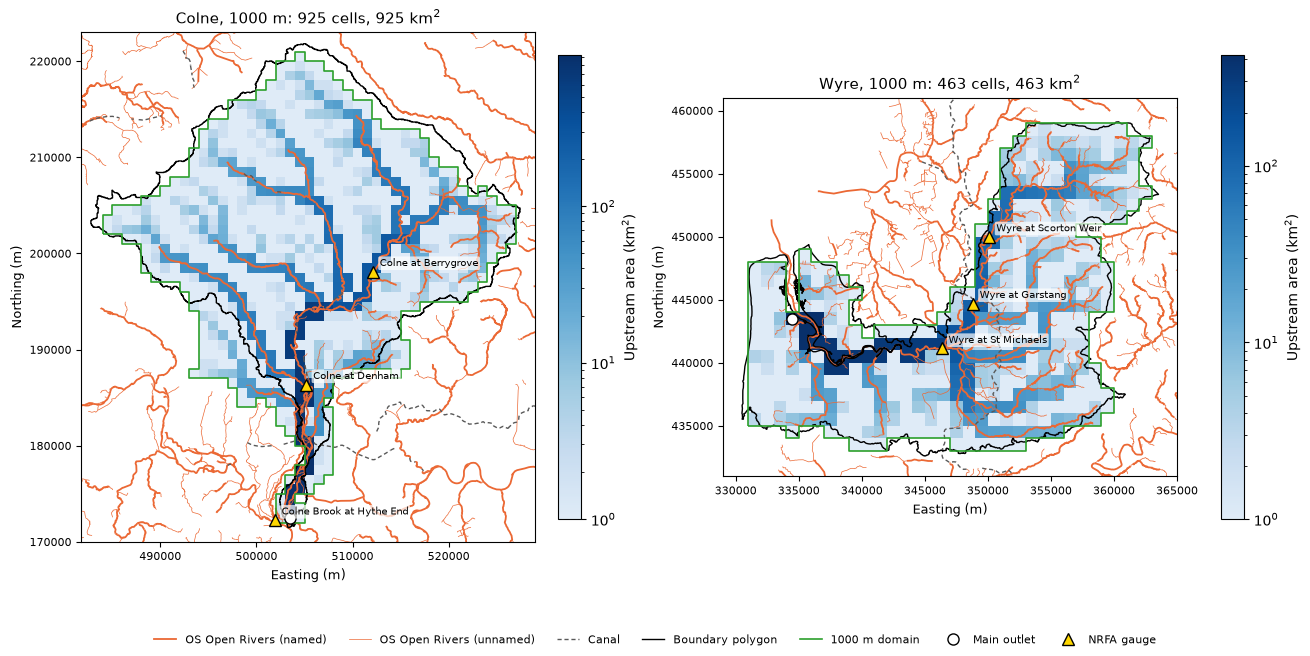

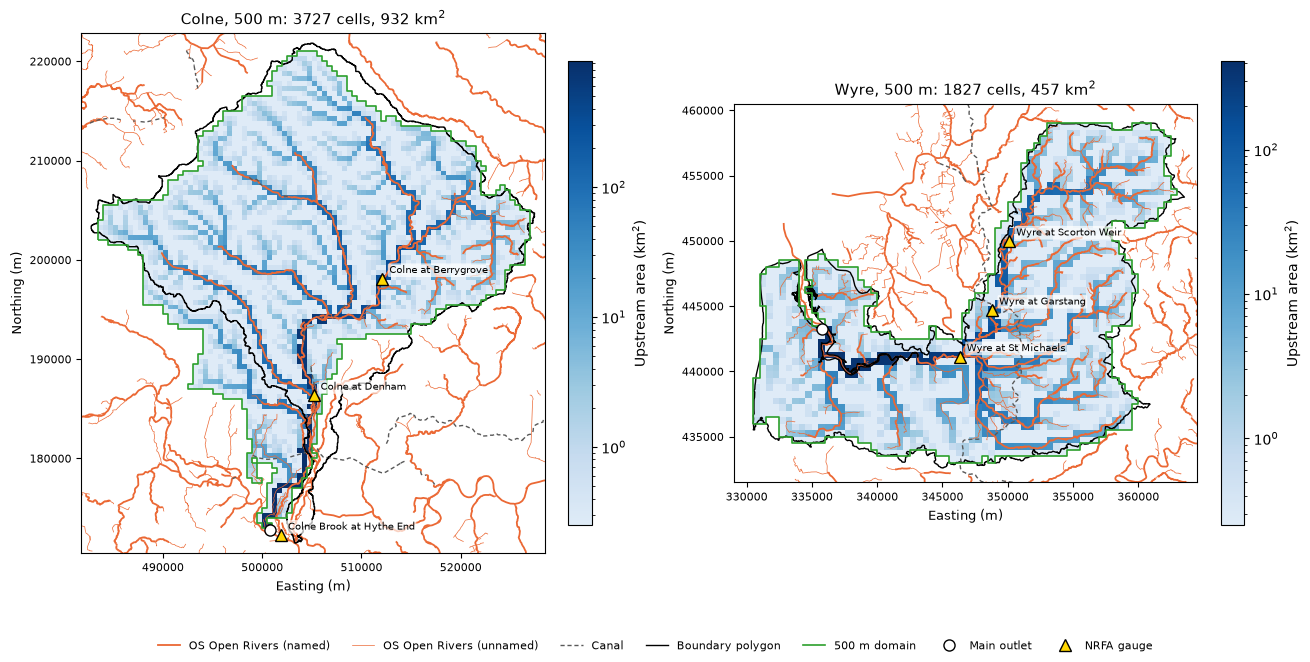

In [8]:
# Blues without its white end, so hillslope cells stand out from the background
BLUES = mcolors.LinearSegmentedColormap.from_list('blues', plt.cm.Blues(np.linspace(0.12, 1, 256)))
RIVER, CANAL = '#eb6834', '0.35'
gdfs = {'colne': colne, 'wyre': wyre}

for g in grids.values():
    fig, axes = plt.subplots(1, 2, figsize=(13, 7), layout='constrained')
    for ax, name in zip(axes, boundaries):
        d = domains[g.res, name]
        w, t = d['window'], d['transform']
        extent = (t.c, t.c + w.width * g.res, t.f - w.height * g.res, t.f)
        minx, miny, maxx, maxy = boundaries[name][0].bounds
        pad = max(g.res, 1000)
        view = (min(extent[0], minx) - pad, max(extent[1], maxx) + pad, min(extent[2], miny) - pad, max(extent[3], maxy) + pad)
        m = d['clip']['fdir'] != NODATA
        area = np.where(m, d['clip']['acc'] * g.cell_km2, np.nan)
        im = ax.imshow(area, extent=extent, cmap=BLUES, norm=mcolors.LogNorm(vmin=g.cell_km2, vmax=np.nanmax(area)),
                       interpolation='nearest')
        fig.colorbar(im, ax=ax, shrink=0.7, label='Upstream area (km$^2$)')

        rivers = gpd.read_file(path_rivers, columns=['form', 'name1'], bbox=(view[0], view[2], view[1], view[3]))
        canal = rivers.form == 'canal'
        named = rivers.name1.notna() & ~canal
        rivers[~named & ~canal].plot(ax=ax, color=RIVER, linewidth=0.5)
        rivers[named].plot(ax=ax, color=RIVER, linewidth=1.3)
        rivers[canal].plot(ax=ax, color=CANAL, linewidth=1, linestyle=(0, (3, 2)))

        gdfs[name].boundary.plot(ax=ax, color='k', linewidth=1)
        gpd.read_file(path_data / f'domain_{g.tag}_bng_{name}.gpkg').boundary.plot(ax=ax, color='tab:green', linewidth=1.2)
        main = d['outlets'][np.argmax(g.acc[d['outlets'][:, 0], d['outlets'][:, 1]])]
        ax.plot(*cell_xy(g, *main), 'o', mfc='w', mec='k', ms=8)
        for station, (x, y, _) in gauges[name].items():
            ax.plot(x, y, '^', mfc='gold', mec='k', ms=8)
            ax.annotate(station.split(' ', 1)[1], (x, y), xytext=(5, 4), textcoords='offset points', fontsize=7.5,
                        bbox=dict(boxstyle='round,pad=0.15', fc='w', ec='none', alpha=0.7))
        ax.set_title(f'{name.title()}, {g.res} m: {m.sum()} cells, {m.sum() * g.cell_km2:.0f} km$^2$', fontsize=11)
        ax.set_xlim(view[:2])
        ax.set_ylim(view[2:])
        ax.set_aspect('equal')
        ax.ticklabel_format(style='plain')
        ax.tick_params(labelsize=8)
        ax.set_xlabel('Easting (m)', fontsize=9)
        ax.set_ylabel('Northing (m)', fontsize=9)
    handles = [Line2D([], [], color=RIVER, lw=1.3, label='OS Open Rivers (named)'),
               Line2D([], [], color=RIVER, lw=0.5, label='OS Open Rivers (unnamed)'),
               Line2D([], [], color=CANAL, lw=1, ls=(0, (3, 2)), label='Canal'),
               Line2D([], [], color='k', lw=1, label='Boundary polygon'),
               Line2D([], [], color='tab:green', lw=1.2, label=f'{g.res} m domain'),
               Line2D([], [], ls='', marker='o', mfc='w', mec='k', ms=8, label='Main outlet'),
               Line2D([], [], ls='', marker='^', mfc='gold', mec='k', ms=8, label='NRFA gauge')]
    fig.legend(handles=handles, loc='outside lower center', ncols=7, fontsize=8, frameon=False)
    plt.show()

## Metadata

In [9]:
sources = {
    'colne': 'CEH Integrated Hydrological Units catchment HA039G13S0001 (River Colne to its Thames confluence at Staines), '
             'saved as `boundaries/colne_ihu-HA039G13S0001/`',
    'wyre': 'Environment Agency WFD Cycle 3 Wyre Management Catchment 3119 (Catchment Data Explorer, downloaded 2026-11-02), '
            'in `boundaries/wyre_ea-management-catchment-3119/`',
}
for (res, name), d in domains.items():
    g = grids[res]
    m = d['clip']['fdir'] != NODATA
    t = d['transform']
    order = np.argsort(-g.acc[d['outlets'][:, 0], d['outlets'][:, 1]])
    outlets = '; '.join(f'({cell_xy(g, r, c)[0]:.0f}, {cell_xy(g, r, c)[1]:.0f}), {g.acc[r, c] * g.cell_km2:.1f} km2, to '
                        f'{"sea" if s else "land outside the domain"}'
                        for (r, c), s in zip(d['outlets'][order[:3]], d['out_to_sea'][order[:3]]))
    if len(order) > 3:
        rest = order[3:]
        outlets += (f'; plus {len(rest)} smaller coastal outlets totalling '
                    f'{g.acc[d["outlets"][rest, 0], d["outlets"][rest, 1]].sum() * g.cell_km2:.1f} km2')
    lines = [
        f'{res} m D8 flow direction for the {name.title()} catchment, British National Grid (EPSG:27700).',
        '',
        f'Cut from `flowdir_{g.tag}_bng.tif` by `notebooks/2026-11-02_4_catchment-flowdir-1km-500m.ipynb`. The domain is made of complete drainage areas, '
        f'chosen to best match the boundary polygon, so no cells drain into it from outside and the only cells draining out are its outlet(s). '
        f'Boundary used: {sources[name]}.',
        '',
        f'Domain: {m.sum()} cells ({m.sum() * g.cell_km2:.0f} km2; boundary polygon {d["area_poly"]:.1f} km2, IoU {iou(g, d["mask"], d["frac"], d["area_poly"]):.3f}). '
        f'Raster: {m.shape[1]} x {m.shape[0]} cells, origin ({t.c:.0f}, {t.f:.0f}). Outside the domain and sea = {NODATA}.',
        '',
        f'Outlet(s), cell centre: {outlets}. Each outlet keeps its direction from the UK grid, so it points at a nodata cell just outside the domain.',
        '',
        'Flow direction encoding: 1 = E, 2 = SE, 4 = S, 8 = SW, 16 = W, 32 = NW, 64 = N, 128 = NE.',
        '',
        'Files:',
        f'- `flowdir_{g.tag}_bng_{name}.tif`: flow direction (int16).',
        f'- `flowacc_{g.tag}_bng_{name}.tif`: upstream cell count, including the cell itself (int32).',
        f'- `dem_{g.tag}_bng_conditioned_{name}.tif`: conditioned cell-minimum DEM (float64, m). See `flowdir_{g.tag}_bng.tif.md`.',
        f'- `domain_{g.tag}_bng_{name}.gpkg`: outline of the domain cells.',
    ]
    (path_data / f'flowdir_{g.tag}_bng_{name}.tif.md').write_text('\n'.join(lines) + '\n')
    print('\n'.join(lines), end='\n\n')

1000 m D8 flow direction for the Colne catchment, British National Grid (EPSG:27700).

Cut from `flowdir_01000_bng.tif` by `notebooks/2026-11-02_4_catchment-flowdir-1km-500m.ipynb`. The domain is made of complete drainage areas, chosen to best match the boundary polygon, so no cells drain into it from outside and the only cells draining out are its outlet(s). Boundary used: CEH Integrated Hydrological Units catchment HA039G13S0001 (River Colne to its Thames confluence at Staines), saved as `boundaries/colne_ihu-HA039G13S0001/`.

Domain: 925 cells (925 km2; boundary polygon 894.6 km2, IoU 0.832). Raster: 45 x 51 cells, origin (483000, 222000). Outside the domain and sea = -9999.

Outlet(s), cell centre: (503500, 172500), 925.0 km2, to land outside the domain. Each outlet keeps its direction from the UK grid, so it points at a nodata cell just outside the domain.

Flow direction encoding: 1 = E, 2 = SE, 4 = S, 8 = SW, 16 = W, 32 = NW, 64 = N, 128 = NE.

Files:
- `flowdir_01000_bng_colne.